In [1]:
import pandas as pd

df = pd.read_csv("data/AEP_hourly.csv", parse_dates=["Datetime"])
print(df.shape)
df.head()

(121273, 2)


,Datetime,AEP_MW
0,2004-12-31 01:00:00,13478.0
1,2004-12-31 02:00:00,12865.0
2,2004-12-31 03:00:00,12577.0
3,2004-12-31 04:00:00,12517.0
4,2004-12-31 05:00:00,12670.0


In [2]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 121273 entries, 0 to 121272
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  121273 non-null  datetime64[us]
 1   AEP_MW    121273 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.9 MB


,Datetime,AEP_MW
count,121273,121273.000000
mean,2011-09-02 03:17:01.553025,15499.513717
min,2004-10-01 01:00:00,9581.000000
25%,2008-03-17 15:00:00,13630.000000
50%,2011-09-02 04:00:00,15310.000000
75%,2015-02-16 17:00:00,17200.000000
max,2018-08-03 00:00:00,25695.000000
std,NaN,2591.399065


In [3]:
df = df.sort_values("Datetime").reset_index(drop=True)
print("Пропуски:", df["AEP_MW"].isna().sum())
print("Дубликаты времени:", df["Datetime"].duplicated().sum())
print(df["Datetime"].min(), "—", df["Datetime"].max())

Пропуски: 0
Дубликаты времени: 4
2004-10-01 01:00:00 — 2018-08-03 00:00:00


In [4]:
df = df.groupby("Datetime", as_index=False)["AEP_MW"].mean()
df = df.set_index("Datetime")

full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Пропущено часов:", len(full_range) - len(df))

df = df.reindex(full_range)
df["AEP_MW"] = df["AEP_MW"].interpolate()
df.index.name = "Datetime"
print("Пропусков после заполнения:", df["AEP_MW"].isna().sum())

Пропущено часов: 27
Пропусков после заполнения: 0


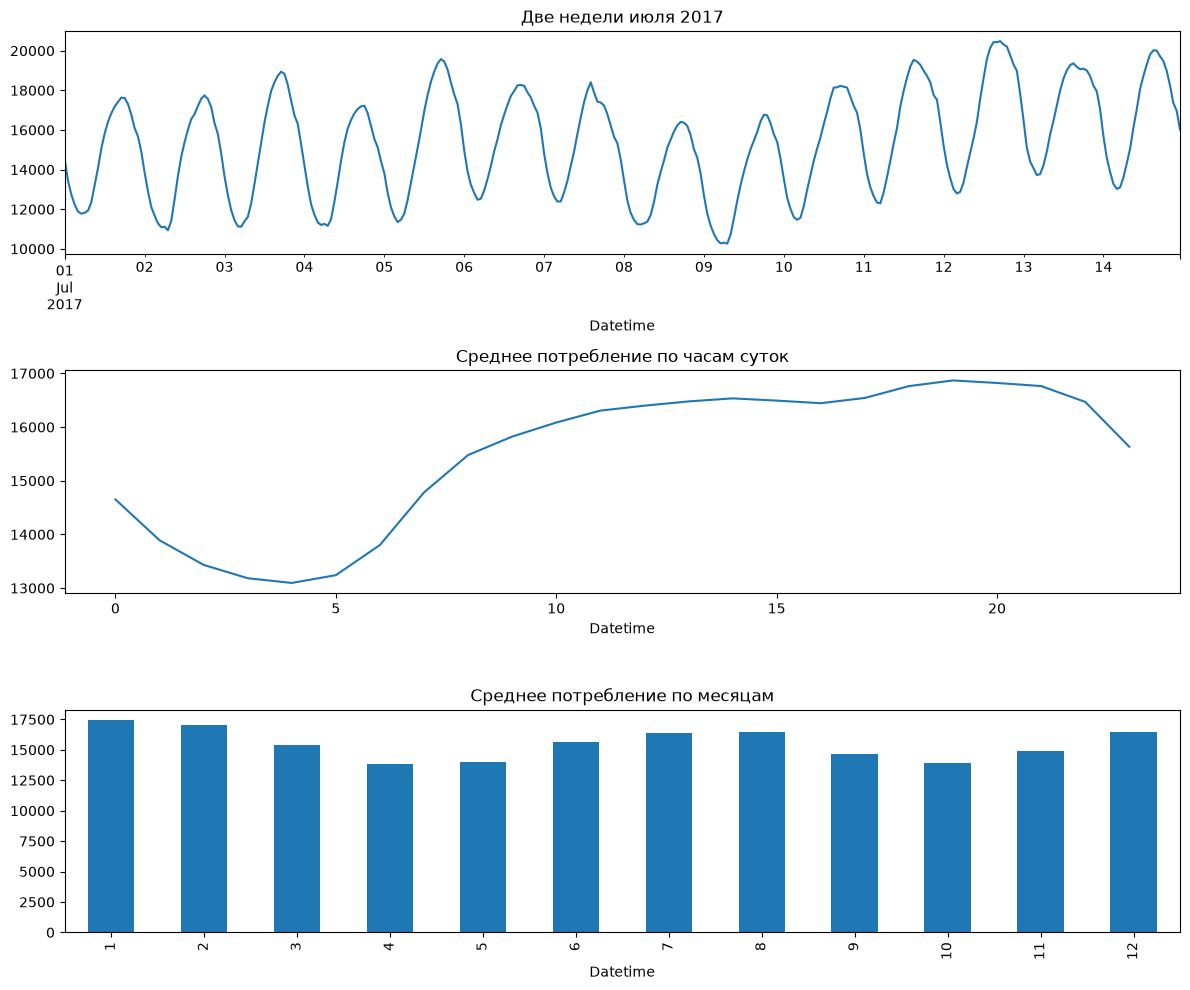

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

df["AEP_MW"].loc["2017-07-01":"2017-07-14"].plot(ax=axes[0], title="Две недели июля 2017")
df.groupby(df.index.hour)["AEP_MW"].mean().plot(ax=axes[1], title="Среднее потребление по часам суток")
df.groupby(df.index.month)["AEP_MW"].mean().plot(kind="bar", ax=axes[2], title="Среднее потребление по месяцам")

plt.tight_layout()
plt.show()

In [6]:
data = pd.DataFrame({"load": df["AEP_MW"]})

data["hour"] = data.index.hour
data["dayofweek"] = data.index.dayofweek
data["month"] = data.index.month
data["is_weekend"] = (data["dayofweek"] >= 5).astype(int)

data["lag_24"] = data["load"].shift(24)
data["lag_168"] = data["load"].shift(168)
data["roll_mean_24"] = data["load"].shift(24).rolling(24).mean()

data = data.dropna()
data.head()

,load,hour,dayofweek,month,is_weekend,lag_24,lag_168,roll_mean_24
Datetime,,,,,,,,
2004-10-08 01:00:00,12468.0,1,4,10,0,12484.0,12379.0,14400.958333
2004-10-08 02:00:00,12046.0,2,4,10,0,12054.0,11935.0,14388.750000
2004-10-08 03:00:00,11749.0,3,4,10,0,11745.0,11692.0,14370.125000
2004-10-08 04:00:00,11784.0,4,4,10,0,11757.0,11597.0,14353.166667
2004-10-08 05:00:00,11919.0,5,4,10,0,12041.0,11681.0,14340.041667


In [7]:
train = data.loc[:"2016-12-31"]
test = data.loc["2017-01-01":]

features = ["hour", "dayofweek", "month", "is_weekend",
            "lag_24", "lag_168", "roll_mean_24"]

X_train, y_train = train[features], train["load"]
X_test, y_test = test[features], test["load"]

print("Обучение:", len(train), "часов")
print("Проверка:", len(test), "часов")

Обучение: 107231 часов
Проверка: 13897 часов


In [8]:
from sklearn.metrics import mean_absolute_error

baseline_pred = X_test["lag_168"]

mae_base = mean_absolute_error(y_test, baseline_pred)
mape_base = ((y_test - baseline_pred).abs() / y_test).mean() * 100

print(f"Baseline MAE: {mae_base:.0f} MW")
print(f"Baseline MAPE: {mape_base:.2f} %")

Baseline MAE: 1475 MW
Baseline MAPE: 9.77 %


In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor

model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
mape = ((y_test - pred).abs() / y_test).mean() * 100

print(f"Model MAE: {mae:.0f} MW")
print(f"Model MAPE: {mape:.2f} %")
print(f"Ошибка уменьшилась на {(1 - mae / mae_base) * 100:.0f} % относительно базовой")

Model MAE: 724 MW
Model MAPE: 4.86 %
Ошибка уменьшилась на 51 % относительно базовой


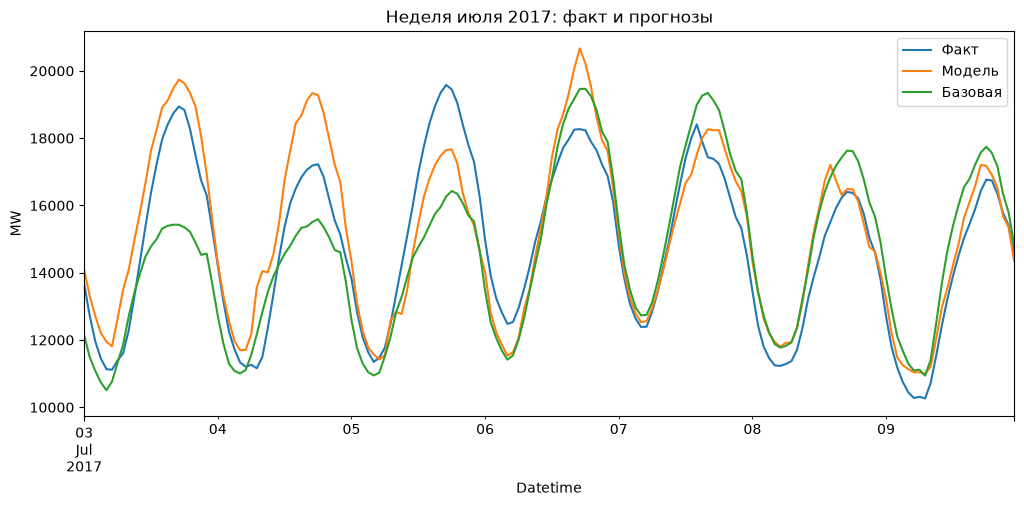

In [10]:
comparison = pd.DataFrame(
    {"Факт": y_test, "Модель": pred, "Базовая": baseline_pred},
    index=y_test.index,
)

comparison.loc["2017-07-03":"2017-07-09"].plot(figsize=(12, 5), title="Неделя июля 2017: факт и прогнозы")
plt.ylabel("MW")
plt.show()

In [11]:
errors = (y_test - pred).abs()
daily_error = errors.groupby(errors.index.date).mean().sort_values(ascending=False)
daily_error.head(10)

2017-02-11    2588.972230
2018-04-24    2346.942280
2018-01-13    2238.567984
2018-01-08    2210.289490
2017-01-11    2114.534734
2018-02-15    2081.893894
2017-01-12    2053.816836
2017-01-17    2052.731097
2018-01-22    2021.776028
2017-12-31    2021.409547
Name: load, dtype: float64

In [12]:
import holidays

us_holidays = holidays.US(years=range(2004, 2019))
holiday_dates = pd.to_datetime(list(us_holidays.keys()))

data["is_holiday"] = data.index.normalize().isin(holiday_dates).astype(int)
print("Праздничных часов:", data["is_holiday"].sum())

Праздничных часов: 3744


In [13]:
def evaluate(features):
    train = data.loc[:"2016-12-31"]
    test = data.loc["2017-01-01":]
    model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42)
    model.fit(train[features], train["load"])
    pred = model.predict(test[features])
    mae = mean_absolute_error(test["load"], pred)
    mape = ((test["load"] - pred).abs() / test["load"]).mean() * 100
    return mae, mape, pred

features_v2 = features + ["is_holiday"]
mae2, mape2, pred2 = evaluate(features_v2)

print(f"Без праздников: MAE {mae:.0f} MW, MAPE {mape:.2f} %")
print(f"С праздниками:  MAE {mae2:.0f} MW, MAPE {mape2:.2f} %")

Без праздников: MAE 724 MW, MAPE 4.86 %
С праздниками:  MAE 724 MW, MAPE 4.87 %


In [14]:
import requests

url = "https://archive-api.open-meteo.com/v1/archive"
frames = []

for year in range(2004, 2019):
    params = {
        "latitude": 39.96,
        "longitude": -82.99,
        "start_date": f"{year}-01-01",
        "end_date": f"{year}-12-31",
        "hourly": "temperature_2m",
        "timezone": "America/New_York",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    h = r.json()["hourly"]
    frames.append(pd.DataFrame({"Datetime": pd.to_datetime(h["time"]), "temp": h["temperature_2m"]}))

weather = pd.concat(frames).drop_duplicates("Datetime").set_index("Datetime")
weather = weather.reindex(data.index).interpolate()

data["temp"] = weather["temp"]
print("Пропусков:", data["temp"].isna().sum())
data["temp"].describe()

Пропусков: 0


count    121128.000000
mean         11.595108
std          11.013396
min         -28.900000
25%           2.800000
50%          12.600000
75%          20.600000
max          38.100000
Name: temp, dtype: float64

In [15]:
features_v3 = features + ["temp"]
mae3, mape3, pred3 = evaluate(features_v3)

print(f"Только время и история: MAE {mae:.0f} MW, MAPE {mape:.2f} %")
print(f"Плюс температура:       MAE {mae3:.0f} MW, MAPE {mape3:.2f} %")

Только время и история: MAE 724 MW, MAPE 4.86 %
Плюс температура:       MAE 484 MW, MAPE 3.29 %


In [16]:
worst_days = daily_error.head(10).index

errors3 = (y_test - pred3).abs()
daily_error3 = errors3.groupby(errors3.index.date).mean()

compare = pd.DataFrame({
    "Ошибка до, MW": daily_error.head(10),
    "Ошибка после, MW": daily_error3.loc[worst_days],
})
compare.round(0)

,"Ошибка до, MW","Ошибка после, MW"
2017-02-11,2589.0,1154.0
2018-04-24,2347.0,2128.0
2018-01-13,2239.0,382.0
2018-01-08,2210.0,843.0
2017-01-11,2115.0,702.0
2018-02-15,2082.0,899.0
2017-01-12,2054.0,937.0
2017-01-17,2053.0,830.0
2018-01-22,2022.0,829.0
2017-12-31,2021.0,711.0


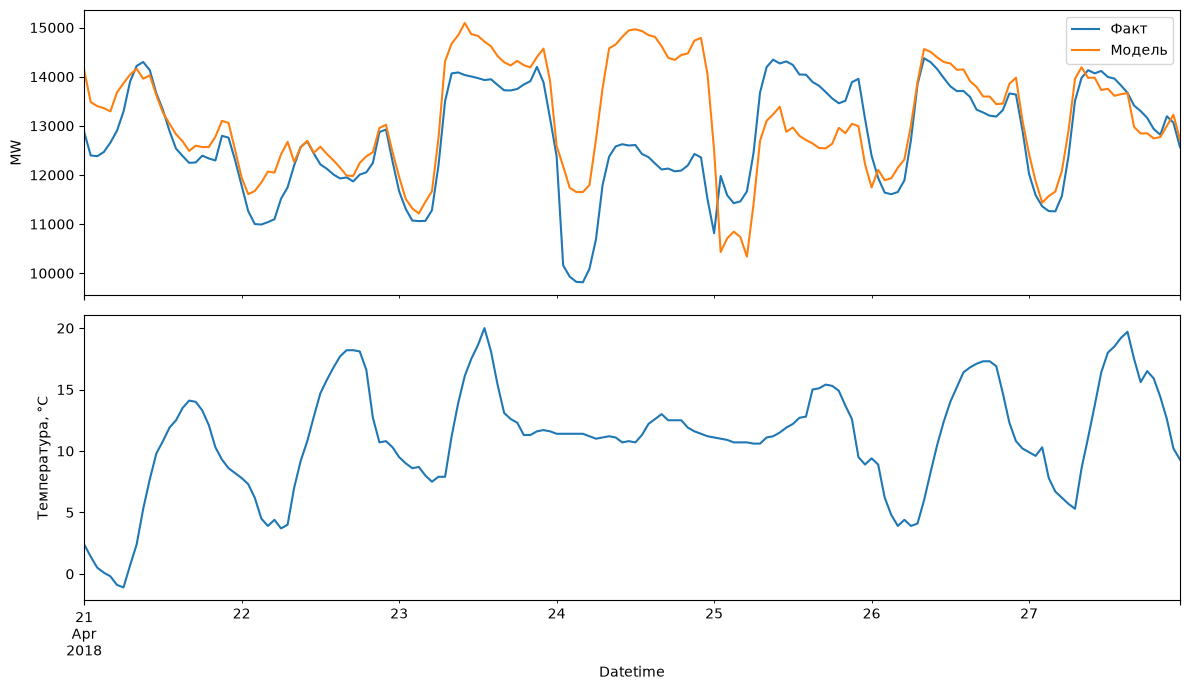

In [17]:
pred3_s = pd.Series(pred3, index=y_test.index)
period = slice("2018-04-21", "2018-04-27")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
y_test.loc[period].plot(ax=axes[0], label="Факт")
pred3_s.loc[period].plot(ax=axes[0], label="Модель")
axes[0].set_ylabel("MW")
axes[0].legend()

data["temp"].loc[period].plot(ax=axes[1])
axes[1].set_ylabel("Температура, °C")

plt.tight_layout()
plt.show()

In [18]:
check = data.loc["2018-04-24", ["load", "lag_24", "lag_168", "temp"]].copy()
check["pred"] = pred3_s.loc["2018-04-24"]
check.iloc[::3].round(0)

,load,lag_24,lag_168,temp,pred
Datetime,,,,,
2018-04-24 00:00:00,12380.0,11668.0,15252.0,11.0,12589.0
2018-04-24 03:00:00,9824.0,11060.0,14466.0,11.0,11651.0
2018-04-24 06:00:00,10692.0,12199.0,15529.0,11.0,12724.0
2018-04-24 09:00:00,12581.0,14086.0,17470.0,11.0,14655.0
2018-04-24 12:00:00,12609.0,13971.0,17158.0,11.0,14964.0
2018-04-24 15:00:00,12232.0,13832.0,16005.0,13.0,14809.0
2018-04-24 18:00:00,12074.0,13749.0,15206.0,12.0,14341.0
2018-04-24 21:00:00,12427.0,14199.0,15752.0,12.0,14734.0


In [19]:
data["temp_lag_24"] = data["temp"].shift(24)
data["temp_diff_24"] = data["temp"] - data["temp_lag_24"]
data["temp_roll_24"] = data["temp"].rolling(24).mean()
data = data.dropna()

features_v4 = features_v3 + ["temp_lag_24", "temp_diff_24", "temp_roll_24"]
mae4, mape4, pred4 = evaluate(features_v4)

print(f"Плюс температура:       MAE {mae3:.0f} MW, MAPE {mape3:.2f} %")
print(f"Плюс динамика температуры: MAE {mae4:.0f} MW, MAPE {mape4:.2f} %")

Плюс температура:       MAE 484 MW, MAPE 3.29 %
Плюс динамика температуры: MAE 444 MW, MAPE 3.01 %


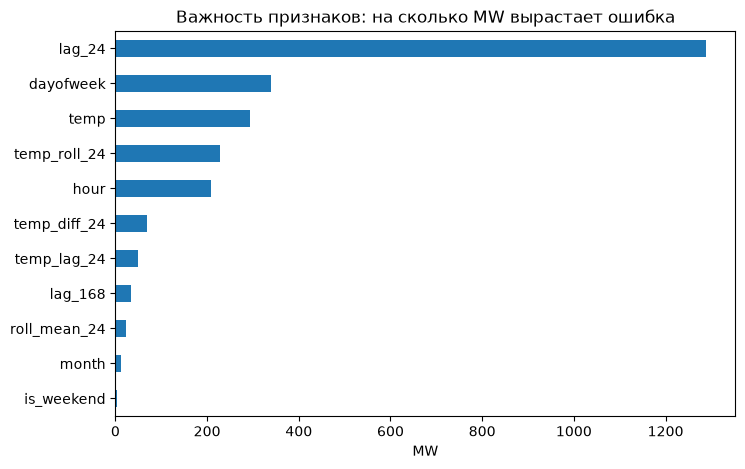

In [20]:
from sklearn.inspection import permutation_importance

train = data.loc[:"2016-12-31"]
test = data.loc["2017-01-01":]

model4 = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42)
model4.fit(train[features_v4], train["load"])

r = permutation_importance(
    model4, test[features_v4], test["load"],
    n_repeats=5, random_state=42, scoring="neg_mean_absolute_error",
)

imp = pd.Series(r.importances_mean, index=features_v4).sort_values()
imp.plot(kind="barh", figsize=(8, 5), title="Важность признаков: на сколько MW вырастает ошибка")
plt.xlabel("MW")
plt.show()

In [21]:
features_v5 = [f for f in features_v4 if f not in ["is_weekend", "month", "roll_mean_24"]]
mae5, mape5, pred5 = evaluate(features_v5)

print(f"Все признаки ({len(features_v4)}):  MAE {mae4:.0f} MW, MAPE {mape4:.2f} %")
print(f"Без лишних ({len(features_v5)}):    MAE {mae5:.0f} MW, MAPE {mape5:.2f} %")

Все признаки (11):  MAE 444 MW, MAPE 3.01 %
Без лишних (8):    MAE 444 MW, MAPE 3.01 %


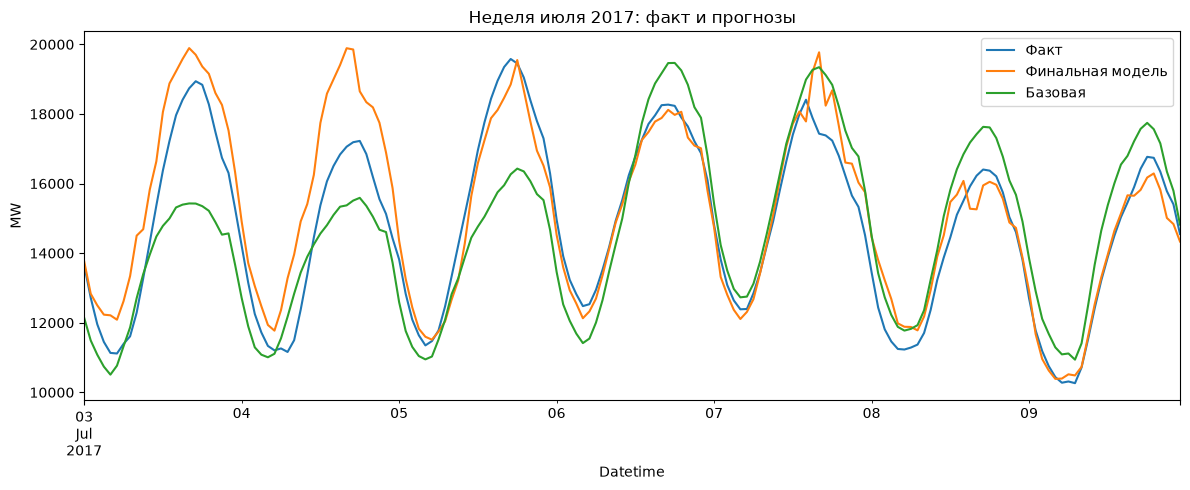

In [22]:
import os
os.makedirs("images", exist_ok=True)

comparison = pd.DataFrame(
    {"Факт": y_test, "Финальная модель": pred5, "Базовая": baseline_pred},
    index=y_test.index,
)

ax = comparison.loc["2017-07-03":"2017-07-09"].plot(figsize=(12, 5), title="Неделя июля 2017: факт и прогнозы")
ax.set_ylabel("MW")
plt.tight_layout()
plt.savefig("images/forecast_week.png", dpi=150)
plt.show()